# conv_03 — 에어 주입 유닛 실린더: 구성 · 시퀀스 · 판정

conv_02 는 **대차 통과 근접 센서**(고정 위치에서 지나가는 금속을 보는 센서)를 다뤘다.
여기서는 유닛 안의 **실린더 스위치와 유닛 위치 센서**를 다룬다. 이 센서들은 대차가 아니라 유닛 자신의 상태를 보므로, "켜짐 길이 8" 대신 **시퀀스 안의 동작 시간·거리**로 판정한다.

| 자료 | 위치 |
|---|---|
| 사이클 표·판정 함수 | `Conv/conv_cyl.py` (`cycle_table`, `cycle_events`, `cyl_daily`, `cyl_judge`) |
| 사이클 표 (캐시) | `cache/conv_feat/cyl_cycles.pkl` — 유닛 3곳 × 40일, 사이클 약 40만 개 |
| PLC 로직 | `IL/IL_file/Air_Supply_Unit.il`, 팀 정리 `Air_Supply2_정상사이클.xlsx` |

## 결론 요약

| 항목 | 결과 |
|---|---|
| 대상 | 에어 주입 유닛 **3곳(전진·후진·에어백)** × 실린더 3개(스톱퍼·노즐·이동대 원점복귀) + 노즐 오픈 밸브. 에어백 유닛도 하루 약 4,000회 동작한다 (§0-1) |
| 재는 법 | 입력·출력 비트는 DB 에서 같은 순간에 읽힌다(P 블록). 카운터는 약 0.26초 늦다. 사이클 하나는 0.5초 샘플이라 못 재지만 **하루 평균은 ms 단위로 정확**하다 (§0-3, §3) |
| 정상 값 | 스톱퍼 전진 0.26 – 0.29초, 후진 0.32 – 0.39초, 노즐 후진 0.29 – 0.33초, 원점복귀 전진 0.34 · 후진 0.73 · 에어백 0.6초. 날짜 간 흔들림 3 – 8 ms (§4) |
| 짧은 신호 | 끝단 후진은 0.5초 펄스라 원본으로는 66 – 79% 만 잡히고, 놓친 사이클에서는 **돌아오는 길의 통과**를 도착으로 잘못 잡는다. PLC 래치 `Rev_PX_CHK` 로 바꿔 모든 지표가 사이클의 99% 이상에서 잡힌다 (§0-3) |
| 전진 유닛 | **09-12 에 유닛 전체가 바뀌었다** (09-11 밤 비가동 중). 끌림 거리 15.3 → 12.3카운트, 에어 주입 0.90 → 0.63초(−30%), 스톱퍼 후진·원점복귀도 빨라짐. 정비·조정으로 보인다 → 점검 1회 후 승인 (§6) |
| 후진 유닛 | **스톱퍼가 천천히 느려지는 중.** 스톱퍼 전진 0.280 → 0.297초(10-17 느려짐 점검), 스톱퍼 후진도 10월부터 장기 기준보다 느림. 끌림 거리는 래치 기준 15.2 로 일정 (원본으로 보던 증가 추세는 착시). conv_02 의 후진 진입 센서 브래킷 흔들림과 같은 유닛 → 유닛 점검 추천 (§6) |
| 진입 센서 이물의 영향 | PLC 는 진입 센서의 **마지막** 상승엣지로 카운터를 다시 맞춘다. 그래서 이물로 두 번 켜져도 스톱퍼는 원래 표식 기준으로 나가고, 대차가 걸리기까지 거리는 대차와 무관하게 일정하다 (§5) |
| PLC 에러 | 40일 동안 운전 중 실린더 시간 초과 에러 0건. 지금 보이는 변화는 모두 에러 한참 전 단계 (§6) |

---
## §0. 정리

### 0-1. 유닛과 실린더 구성

유닛 3곳이 같은 구조다. 대차가 오면 스톱퍼로 대차를 잡고, 대차에 끌려가는 동안 노즐을 붙여 금형 실린더(중형 CY)에 에어를 넣고, 끝에서 놓은 뒤 원점으로 돌아온다.

| 장치 | 구동 | 감지 | 전진 유닛 | 후진 유닛 | 에어백 유닛 |
|---|---|---|---|---|---|
| **스톱퍼 실린더** | SOL | 전진감지 · 후진감지 (실린더 스위치 2개) | P00470 / P00455 · P00456 | P00474 / P0045D · P0045E | P0028A / P00134 · P00135 |
| **노즐 실린더** (주입구 1·2, SOL 하나로 같이) | SOL | **후진감지만** (실린더 스위치) | P00471 / P00457 (노즐 1·2 **입력 공유**) | P00475 / P0045F (공유) | P0028B / P00136 · P00137 (**따로**) |
| **이동대 원점복귀** (로드리스 실린더) | SOL | 정위치 (근접) | P00472 / P00452 | P00476 / P0045A | P0028C / P00131 |
| 이동대 끌림 구간 (대차가 끌고 감) | 대차 | 정위치 OFF → 끝단 후진 (근접), 비상 (근접) | P00453, P00454 | P0045B, P0045C | P00132, P00133 |
| 노즐 오픈 밸브 (에어 주입) | SOL | 없음 | P00473 | P00477 | P00243 |
| 트리거 | — | 진입 카운터가 설정값에 닿을 때 | R00055 30–33 (진입 P00451) | R00060 27–30 (진입 P00459) | R00050 96–99 (**클로징 P00154** 카운터를 빌려 씀, 자체 진입 P00130 은 꺼짐) |

- 실린더는 유닛당 3개, 모두 9개다. 감지 입력은 유닛당 8개(정위치·끝단·비상·스톱퍼 2·노즐 1–2·진입·1번 대차)다.
- 노즐 전진 쪽은 감지 센서가 없다. 노즐은 **출발(후진감지 꺼짐)과 복귀(후진감지 켜짐)** 만 잴 수 있다.
- 전진·후진 유닛은 노즐 1·2 가 입력 하나를 공유해서 노즐 하나만 늦어져도 구분할 수 없다. 에어백 유닛은 따로 본다.

### 0-2. 시퀀스와 PLC 타이머·에러

| 단계 | 일어나는 일 | 이 단계에서 잴 수 있는 것 | PLC 에러 (시간 초과) |
|---|---|---|---|
| 1 | 진입 카운터가 설정값 → **스톱퍼 SOL ON** → 후진감지 OFF → 전진감지 ON | 스톱퍼 전진 출발·전진 시간 (초) | 스톱퍼 전진 2초 |
| 2 | 대차가 스톱퍼에 걸려 이동대가 끌려감 → **정위치 OFF** | 대차가 걸리기까지 거리 (카운트) | — (전진·후진 유닛은 타임아웃 없음, 에어백만 5초) |
| 3 | 정위치 OFF 순간 **노즐 SOL ON** → 노즐 후진감지 OFF | 노즐 전진 출발 (초) | 노즐 전진 1초 |
| 4 | 후진감지 OFF 0.5초 뒤 **노즐 오픈** (에어 주입) | — (PLC 타이머) | — |
| 5 | 이동대가 끝까지 → **끝단 후진 ON** → 오픈 닫힘, 0.5초 뒤 노즐 SOL OFF | 끌림 거리 (카운트), 에어 주입 시간 (초) | 비상 감지 즉시 · 오픈 최대 10초(에어백 3초) |
| 6 | 노즐 후진감지 ON → **스톱퍼 SOL OFF** → 전진감지 OFF → 후진감지 ON | 노즐 후진 시간, 스톱퍼 후진 출발·후진 시간 (초) | 노즐 후진 2초, 스톱퍼 후진 2초 |
| 7 | 스톱퍼 후진감지 ON 순간 **원점복귀 SOL ON** → 정위치 ON → SOL OFF | 원점복귀 시간 (초) | 원점복귀 2초 |

### 0-3. 시간을 재는 원칙

**① 같은 블록끼리 비교한다.**
- DB 수집기는 한 번에 PLC 블록을 **K → M → P → D(약 2,900워드) → R → T** 순서로 읽고 한 시각을 찍는다.
- 입력·출력 비트(P)는 같은 순간 값이다. 카운터(R)는 약 **0.26초 늦게** 읽힌다. 카운터 30 에서 나가는 스톱퍼 SOL 이 카운터 기준으로 0.26초 늦게 보이는 것이 그 증거다.
- 그래서 실린더 시간은 P 비트끼리 잰다. 카운터는 대차 번호와 거리(끌림·걸림)에만 쓴다. 거리는 같은 카운터의 차이라 시차가 상쇄된다.

**② 사이클 하나가 아니라 하루 평균으로 본다.**
- 비트가 바뀐 시각은 "바뀌기 전 샘플과 바뀐 샘플의 중간"이다. 실린더 동작(0.1 – 0.7초)은 샘플 간격(0.5초)과 비슷하거나 짧아서, 사이클 하나의 값은 0 아니면 약 0.5 로 나온다 (§3).
- 하지만 샘플 시점은 사이클마다 무작위라 **평균은 치우치지 않는다.** 하루 약 4,000 – 4,500 사이클의 평균은 표준오차 수 ms 다.
- 그래서 판정은 일별 평균의 변화로 한다. 사이클 하나가 2초를 넘는 극단적인 경우는 PLC 에러 비트가 잡는다.

**③ 짧은 신호는 PLC 래치로 대체한다.** 사이클마다 잡히는 비율 (10-16)

| 동작 | 원본 신호 | 원본 | 대체 (PLC 래치) | 대체 |
|---|---|---|---|---|
| 이동대 끝단 도착 | 끝단 후진 P00453 · P0045B · P00132 (약 0.5초 펄스) | 67 · 79 · 72% | `Air_Supply2/3/_Rev_PX_CHK` (끝단 후진 순간 SET, 원점복귀까지 유지) | **99.5 – 100%** |
| 스톱퍼 전진·후진 도착, 노즐 복귀, 원점복귀 도착 | 실린더 스위치·정위치 (상태가 몇 초 유지) | 99.5% | 그대로 | — |

- 원본으로 재면 놓친 사이클에서 다른 펄스를 잡는다. 후진 유닛은 원점복귀 때 이동대가 **끝단 센서 앞을 한 번 더 지나가는데**, 첫 도착을 놓친 사이클에서는 이 통과를 도착으로 잡아 끌림 거리가 1.2카운트 길게 나왔다. 그 비율이 날마다 달라져 **증가 추세처럼 보였다.**
- 전진 유닛은 원본이 잡은 사이클만 보면 래치와 똑같지만, 놓친 사이클이 끌림이 긴 쪽이라 평균이 0.7카운트 짧게 치우쳤다.
- 래치는 비상 감지·주입 시간 초과·에러 중 리셋으로도 켜진다. 그런 사이클은 그 자체가 이상 사이클이다.
- 짧은 펄스의 **평균 길이**는 놓쳐도 구할 수 있다. 켜져 있던 샘플 수 × 샘플 간격 ÷ 사이클 수 = 사이클당 평균 켜짐 시간 (샘플 위상이 무작위라 치우침 없음).

**④ 멈췄다 이어진 사이클은 뺀다.** 사이클(스톱퍼 SOL ON → 다음 ON)이 30초를 넘으면 중간에 라인이 멈춘 것이다. 09-12 06:11 사이클 하나가 42분짜리라 하루 평균을 크게 왜곡했다.

### 0-4. 지표

| 지표 | 단위 | 재는 것 | 변하면 의심 |
|---|---|---|---|
| `stop_fwd_start` · `stop_fwd_time` | 초 | 스톱퍼 SOL ON → 후진감지 OFF · 전진감지 ON | 공압 저하, 솔밸브 응답, 실린더 패킹·마찰 |
| `stop_rev_start` · `stop_rev_time` | 초 | 스톱퍼 SOL OFF → 전진감지 OFF · 후진감지 ON | 같음 (배기 쪽) |
| `nozzle_fwd_start` | 초 | 노즐 SOL ON → 노즐 후진감지 OFF | 노즐 실린더·공압 |
| `nozzle_rev_time` | 초 | 노즐 SOL OFF → 노즐 후진감지 ON | 같음 |
| `return_time` | 초 | 스톱퍼 후진감지 ON(= 원점복귀 SOL ON) → 정위치 ON | 로드리스 실린더·레일 마찰·공압 |
| `catch_cnt` | 카운트 | 스톱퍼 전진감지 ON → 정위치 OFF | 대차가 스톱퍼에 걸리는 지점 (트리거 위치·대차 걸림쇠) |
| `drag_cnt` | 카운트 | 정위치 OFF → 끝단 후진 래치 ON | 이동대가 끌려가는 거리 = 정위치·끝단 센서 간격 (센서 이동·조정) |
| `air_time` | 초 | 노즐 오픈 ON → OFF | **에어 주입량** (끌림 거리와 속도로 정해짐) — 공정 결과에 직접 영향 |

### 0-5. 판정 규칙 — conv_02 와 같은 틀

| 상태 | 조건 | 수준 | 자동 승인 |
|---|---|---|---|
| **느려짐** | 시간 지표의 일별 평균이 단기 기준 + 5σ 초과 | 점검 추천 | **안 함** — 실린더·공압 노후 쪽 (conv_02 의 이물과 같음) |
| 빨라짐 | 시간 지표가 단기 기준 − 5σ 미만 | 관찰 | 3 가동일 유지 시 (정비·압력 조정 등) |
| **거리 변화** | 카운트 지표가 ±5σ 밖 | 점검 추천 1회 | 3 가동일 유지 시 (센서·이동대 조정) |
| 장기 기준 이탈 | 최근 7 가동일 중앙값이 장기 기준(처음 3 가동일)에서 ±3σ 밖 | 추세 표시 | 장기 기준은 갱신 안 함 |
| PLC 에러 | 운전 중 시간 초과·비상 감지 | **경고** | 안 함 |

σ = 그 지표의 날짜 간 흔들림 (연속한 날 차이의 중앙값으로 잡아 계단 변화에 끌려가지 않게, 최소 3 ms · 0.05 카운트). 기준값은 `conv_cyl.py` 의 `Z_TOL`, `Z_LONG`, `N_ACCEPT_CYL`, `N_REF`.

---
## §1. 준비

In [1]:
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib, matplotlib.pyplot as plt
import matplotlib.dates as mdates

ROOT_DIR = os.path.abspath(os.path.join(os.getcwd(), "..") if os.path.basename(os.getcwd()) == "Conv" else os.getcwd())
CONV_DIR = os.path.join(ROOT_DIR, "Conv")
for p in (ROOT_DIR, CONV_DIR):
    if p not in sys.path:
        sys.path.insert(0, p)
matplotlib.rcParams["font.family"] = "AppleGothic"
matplotlib.rcParams["axes.unicode_minus"] = False
matplotlib.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
warnings.simplefilter("ignore", RuntimeWarning)

from conv_cyl import (UNITS, METRICS, LABEL, TIME_METRICS, COUNT_METRICS, cycle_table, cycle_events,
                      cyl_daily, cyl_judge, Z_TOL, Z_LONG)
from conv_grid import day_events, SENSORS

START, END = "2026-09-10", "2026-10-19"
FEAT_DIR = os.path.join(ROOT_DIR, "cache", "conv_feat")
CYC_PATH = os.path.join(FEAT_DIR, "cyl_cycles.pkl")
DEMO_DAY = "2026-10-16"

SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, CRITICAL = "#2a78d6", "#eb6834", "#1baf7a", "#d03b3b"
PURPLE, YELLOW = "#7a5cc7", "#c99a06"
UNIT_COLOR = {"md_fwd": ORANGE, "md_rev": PURPLE, "airbag": AQUA}
UNIT_NAME = {u: UNITS[u]["name"] for u in UNITS}


def style_ax(ax, grid="y"):
    ax.set_facecolor(SURFACE)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(AXIS)
    ax.tick_params(colors=INK2, labelsize=8)
    if grid:
        ax.grid(axis=grid, color=GRID, linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)

In [2]:
# 사이클 표 — 없으면 40일을 새로 만든다 (약 20초). 진입 센서 이벤트로 대차 번호를 붙인다
ENTRY = {"md_fwd": "P00451", "md_rev": "P00459", "airbag": None}
if os.path.exists(CYC_PATH):
    C = pd.read_pickle(CYC_PATH)
else:
    parts = []
    for d in pd.date_range(START, END).strftime("%Y-%m-%d"):
        ev = day_events(d, SENSORS.loc[["P00140", "P00451", "P00459"]])
        for u in UNITS:
            we = ev[ev.sensor == ENTRY[u]][["t", "wagon"]] if (ENTRY[u] and len(ev)) else None
            c = cycle_table(d, u, we)
            if len(c):
                parts.append(c)
    C = pd.concat(parts, ignore_index=True)
    C.to_pickle(CYC_PATH)

D = cyl_daily(C)
J = cyl_judge(D)
print(f"사이클 {len(C):,} (운전 중·중단 제외 {int((C.run & ~C.interrupted).sum()):,}) · 유닛별 가동일 {D.groupby('unit').size().to_dict()}")
D.groupby("unit").cycles.median().rename("하루 사이클 중앙").to_frame().T

사이클 401,307 (운전 중·중단 제외 399,238) · 유닛별 가동일 {'airbag': 31, 'md_fwd': 31, 'md_rev': 31}


unit,airbag,md_fwd,md_rev
하루 사이클 중앙,3991.0,4420.0,4419.0


---
## §2. 사이클 하나의 모양

10-16 하루, 신호마다 사이클 안 첫 켜짐(▲)·꺼짐(▼) 시각의 평균(스톱퍼 SOL ON = 0). 가는 선은 10 – 90% 범위다 (0.5초 샘플링 폭이 섞여 있다).

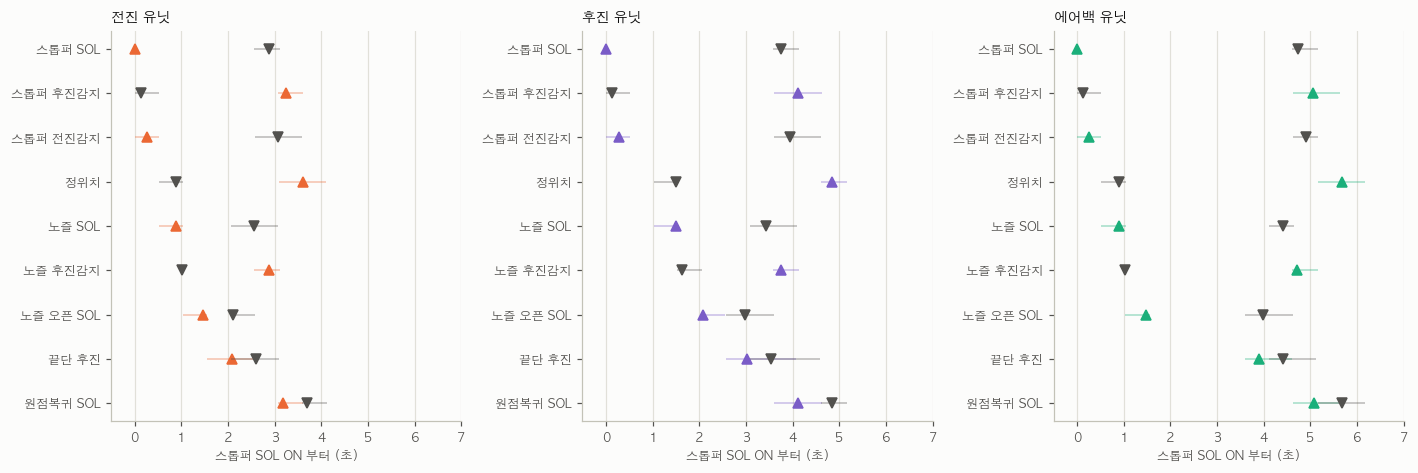

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), facecolor=SURFACE, sharex=True)
for ax, u in zip(axes, UNITS):
    E = cycle_events(DEMO_DAY, u)
    sigs = list(dict.fromkeys(E.signal))
    for y, s in enumerate(sigs[::-1]):
        for edge, mk, c in [("ON", "^", UNIT_COLOR[u]), ("OFF", "v", INK2)]:
            v = E[(E.signal == s) & (E.edge == edge)].rel_s.dropna()
            if len(v) < 50:
                continue
            ax.hlines(y, np.percentile(v, 10), np.percentile(v, 90), color=c, lw=1, alpha=0.4)
            ax.plot(v.mean(), y, mk, color=c, ms=7)
    ax.set_yticks(range(len(sigs)), sigs[::-1], fontsize=8)
    ax.set_xlim(-0.5, 7)
    ax.set_xlabel("스톱퍼 SOL ON 부터 (초)", color=INK2, fontsize=8)
    ax.set_title(UNIT_NAME[u], color=INK, fontsize=9, loc="left")
    style_ax(ax, grid="x")
plt.tight_layout()
plt.show()

세 유닛의 순서는 IL 시퀀스와 같다. 차이는 끌림 구간 길이다. 에어백 유닛은 끌림이 길어서(약 32카운트) 에어 주입이 2.5초, 전진은 0.63초, 후진은 0.88초다.
(이 그림의 "끝단 후진"은 원본 비트라, 놓친 사이클에서 돌아오는 길의 통과가 섞여 있다. 지표는 래치로 잰다.)

---
## §3. 사이클 하나로는 못 재고, 하루 평균은 정확하다

10-16 전진 유닛 스톱퍼 전진 시간. 사이클마다 0 아니면 약 0.5초(샘플 한 칸)로 나온다. 하지만 하루 평균은 0.27초로 안정적이고, 표준오차는 수 ms 다.

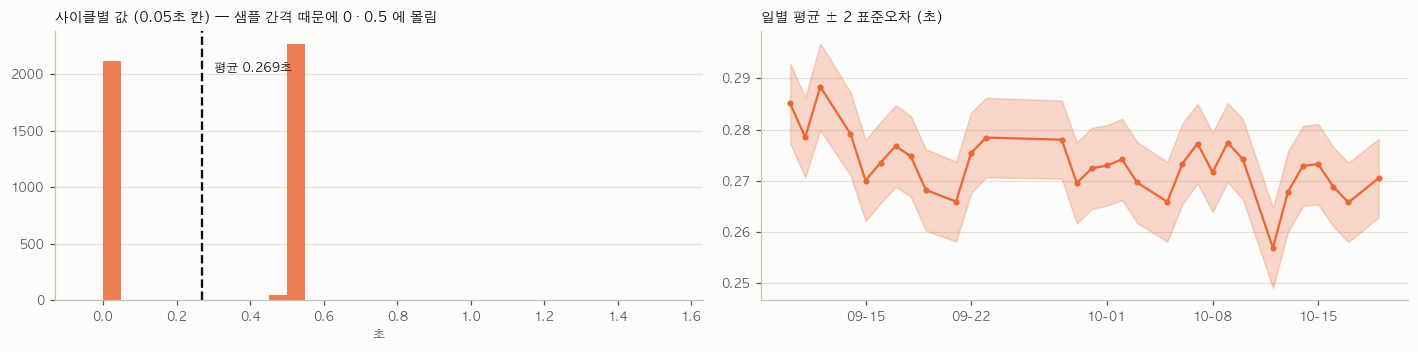

하루 표준오차 중앙값: 3.9 ms


In [4]:
c = C[(C.unit == "md_fwd") & (C.day == DEMO_DAY) & C.run & ~C.interrupted]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.3), facecolor=SURFACE)
axes[0].hist(c.stop_fwd_time.dropna(), bins=np.arange(-0.05, 1.6, 0.05), color=ORANGE, alpha=0.85)
axes[0].axvline(c.stop_fwd_time.mean(), color=INK, lw=1.5, ls="--")
axes[0].annotate(f"평균 {c.stop_fwd_time.mean():.3f}초", (c.stop_fwd_time.mean(), axes[0].get_ylim()[1] * 0.85),
                 xytext=(8, 0), textcoords="offset points", fontsize=8, color=INK)
axes[0].set_title("사이클별 값 (0.05초 칸) — 샘플 간격 때문에 0 · 0.5 에 몰림", color=INK, fontsize=9, loc="left")
axes[0].set_xlabel("초", color=INK2, fontsize=8)
f = D[D.unit == "md_fwd"].sort_values("day")
se = C[(C.unit == "md_fwd") & C.run & ~C.interrupted].groupby("day").stop_fwd_time.agg(lambda x: x.std() / np.sqrt(x.count()))
se = se.reindex(f.day)
axes[1].fill_between(f.day, f.stop_fwd_time - 2 * se.to_numpy(), f.stop_fwd_time + 2 * se.to_numpy(), color=ORANGE, alpha=0.25)
axes[1].plot(f.day, f.stop_fwd_time, marker="o", ms=3, color=ORANGE)
axes[1].set_title("일별 평균 ± 2 표준오차 (초)", color=INK, fontsize=9, loc="left")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
for ax in axes:
    style_ax(ax)
plt.tight_layout()
plt.show()
print(f"하루 표준오차 중앙값: {se.median() * 1000:.1f} ms")

---
## §4. 40일 일별 평균 — 유닛 3곳 × 주요 지표

점은 일별 평균, 회색 띠는 장기 기준 ±3σ, 굵은 선은 단기 기준(승인되면 계단처럼 바뀐다). 빨간 점은 점검 추천(느려짐·거리 변화), 노란 점은 관찰(빨라짐).

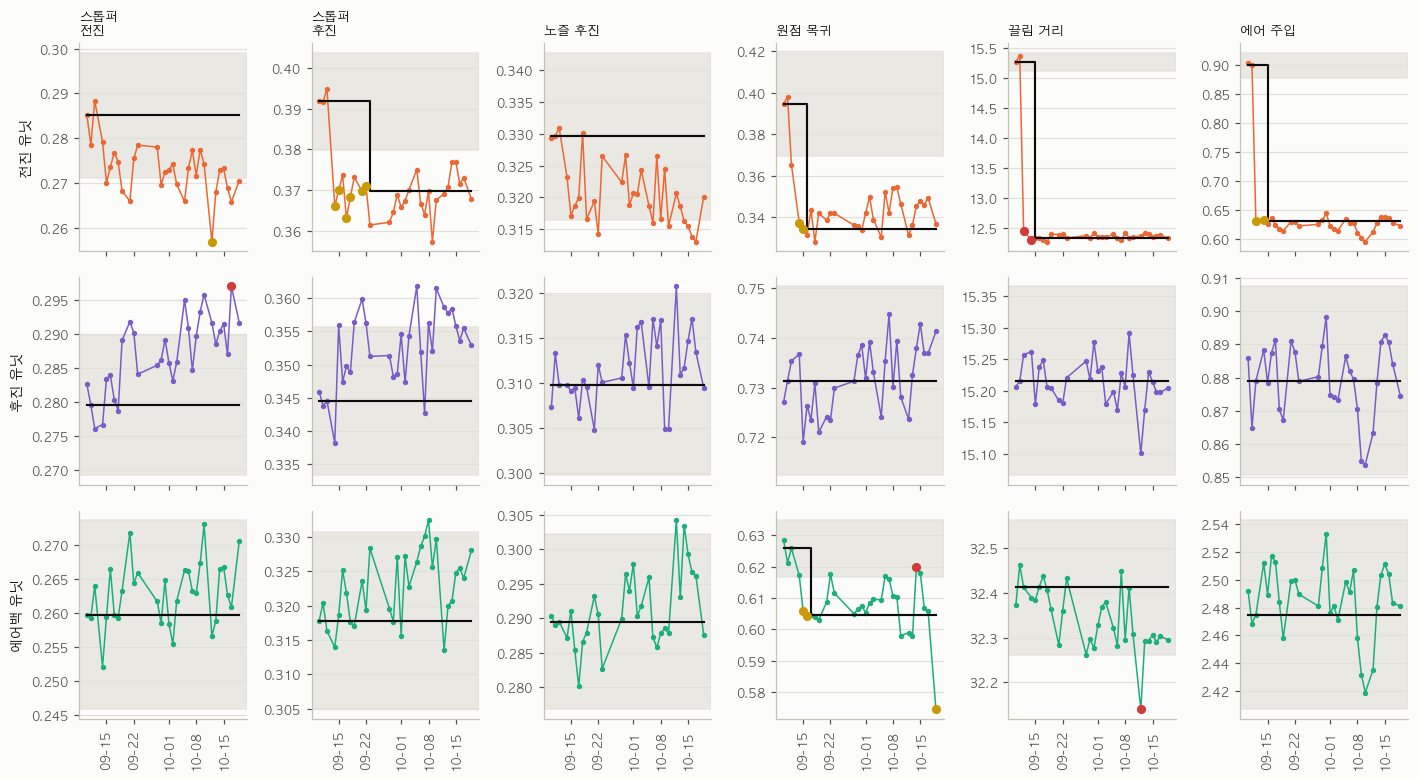

In [5]:
SHOW = ["stop_fwd_time", "stop_rev_time", "nozzle_rev_time", "return_time", "drag_cnt", "air_time"]
fig, axes = plt.subplots(3, len(SHOW), figsize=(13, 7.2), facecolor=SURFACE, sharex=True)
for i, u in enumerate(UNITS):
    for k, m in enumerate(SHOW):
        ax = axes[i, k]
        col = m if m in J[J.unit == u].metric.unique() else f"{m}_1"
        s = J[(J.unit == u) & (J.metric == col)].sort_values("day")
        if s.empty:
            ax.set_visible(False)
            continue
        ax.axhspan(s.long_ref.iloc[0] - 3 * s.sigma.iloc[0], s.long_ref.iloc[0] + 3 * s.sigma.iloc[0], color=GRID, alpha=0.7)
        ax.plot(s.day, s.value, marker="o", ms=2.5, lw=1, color=UNIT_COLOR[u])
        ax.step(s.day, s.level, where="post", color=INK, lw=1.4)
        bad = s[s.sev == 2]
        obs = s[s.sev == 1]
        ax.plot(bad.day, bad.value, "o", ms=5, color=CRITICAL)
        ax.plot(obs.day, obs.value, "o", ms=5, color=YELLOW)
        if i == 0:
            ax.set_title(LABEL[m].replace(" 시간", "").replace("스톱퍼 ", "스톱퍼\n"), color=INK, fontsize=8.5, loc="left")
        if k == 0:
            ax.set_ylabel(UNIT_NAME[u], color=INK, fontsize=9)
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
        ax.tick_params(axis="x", rotation=90)
        style_ax(ax)
plt.tight_layout()
plt.show()

In [6]:
summ = J.groupby(["unit", "metric"]).agg(장기기준=("long_ref", "first"), 흔들림σ=("sigma", "first"),
                                        최근값=("value", "last"), 장기이탈z=("z_long", "last")).reset_index()
summ["unit"] = summ.unit.map(UNIT_NAME)
summ["지표"] = summ.metric.map(lambda m: LABEL.get(m, LABEL.get(m.rsplit("_", 1)[0], m)) + (f" (노즐 {m[-1]})" if m[-2:] in ("_1", "_2") else ""))
summ[["unit", "지표", "장기기준", "흔들림σ", "최근값", "장기이탈z"]].round(4)

,unit,지표,장기기준,흔들림σ,최근값,장기이탈z
0,에어백 유닛,에어 주입 시간,2.4748,0.0227,2.4810,0.3771
1,에어백 유닛,대차가 걸리기까지,6.6555,0.0500,6.7316,1.5210
2,에어백 유닛,끌림 거리,32.4116,0.0500,32.2948,-2.3810
3,에어백 유닛,노즐 전진 출발 (노즐 1),0.1165,0.0039,0.1084,-0.0496
4,에어백 유닛,노즐 전진 출발 (노즐 2),0.1030,0.0035,0.0959,0.2538
5,에어백 유닛,노즐 후진 시간 (노즐 1),0.2895,0.0042,0.2876,1.6833
6,에어백 유닛,노즐 후진 시간 (노즐 2),0.3083,0.0054,0.3052,0.4914
7,에어백 유닛,원점 복귀 시간,0.6258,0.0030,0.5744,-6.7071
8,에어백 유닛,스톱퍼 전진 출발,0.1224,0.0046,0.1252,-0.1708
9,에어백 유닛,스톱퍼 전진 시간,0.2597,0.0046,0.2705,0.6347


---
## §5. 진입 센서 이물은 스톱퍼에 영향을 주나

conv_02 에서 전진 진입 센서(P00451)는 이물 대차에서 일찍·두 번 켜졌다. 스톱퍼가 진입 엣지 기준 30카운트에 나간다면, 일찍 켜지는 대차는 스톱퍼도 일찍 나가서 **대차가 걸리기까지 더 오래 기다려야** 한다.

대차·날짜별로 "대차가 걸리기까지 거리(catch_cnt)"와 진입 센서의 앞 끝 편차를 비교한다 (10-13 – 10-17).

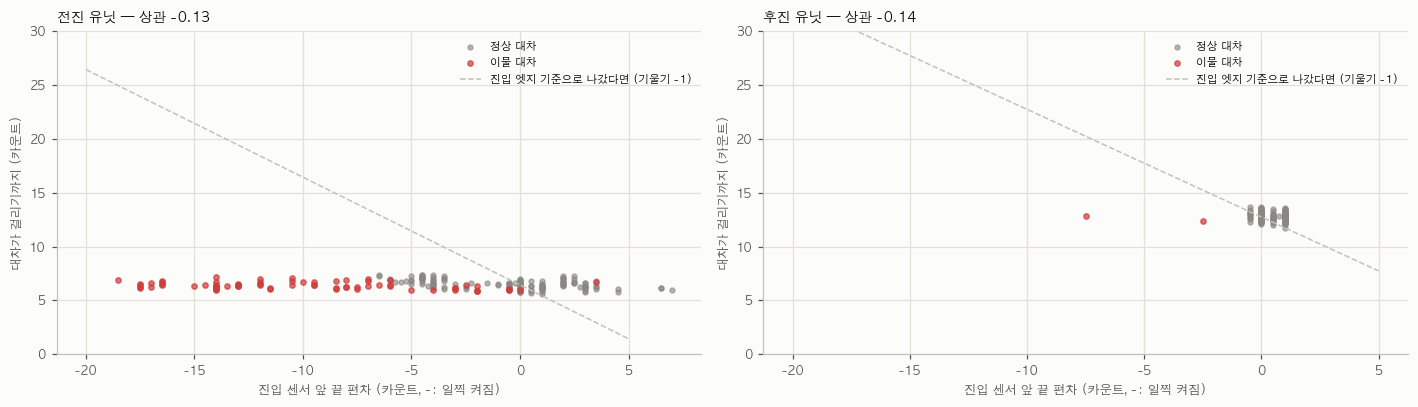

In [7]:
JG = pd.read_pickle(os.path.join(FEAT_DIR, "wagon_sensor_judged.pkl"))
wk = C[C.run & ~C.interrupted & C.wagon.notna() & (C.day >= "2026-10-13") & (C.day <= "2026-10-17")]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), facecolor=SURFACE)
rows = []
for ax, (u, bit) in zip(axes, [("md_fwd", "P00451"), ("md_rev", "P00459")]):
    cw = wk[wk.unit == u].groupby(["day", "wagon"]).catch_cnt.mean().rename("catch").reset_index()
    j = JG[JG.sensor == bit][["day", "wagon", "rise_off", "rearm", "state"]]
    m = cw.merge(j, on=["day", "wagon"])
    foreign = m.state.str.startswith("이물")
    ax.scatter(m.rise_off[~foreign], m.catch[~foreign], s=10, color=MUTED, alpha=0.6, label="정상 대차")
    ax.scatter(m.rise_off[foreign], m.catch[foreign], s=12, color=CRITICAL, alpha=0.7, label="이물 대차")
    x = np.linspace(-20, 5, 2)
    ax.plot(x, m.catch.median() - x, ls="--", color=AXIS, lw=1, label="진입 엣지 기준으로 나갔다면 (기울기 -1)")
    ax.set_xlabel("진입 센서 앞 끝 편차 (카운트, -: 일찍 켜짐)", color=INK2, fontsize=8)
    ax.set_ylabel("대차가 걸리기까지 (카운트)", color=INK2, fontsize=8)
    ax.set_title(f"{UNIT_NAME[u]} — 상관 {np.corrcoef(m.rise_off, m.catch)[0, 1]:+.2f}", color=INK, fontsize=9, loc="left")
    ax.set_ylim(0, 30)
    style_ax(ax, grid="both")
    ax.legend(fontsize=7, frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

대차가 걸리기까지 거리는 이물 대차에서도 정상 대차와 같다. 스톱퍼가 **원래 표식 기준**으로 나간다는 뜻이다.

이유는 PLC 에 있다. 진입 센서의 상승엣지마다 카운터를 1 로 리셋하므로(`LOADP P00451 → MOV 1 R00055`), 이물에 한 번 켜지고 원래 표식에 다시 켜지면 **두 번째 엣지로 다시 맞춰진다.** conv_02 의 "2차 리셋"이 바로 그것이다.

그래서 지금 수준의 이물은 유닛 동작에 영향이 없다. 영향이 생기는 경우는 둘이다.
- 이물이 원래 표식에 붙어서 펄스가 나뉘지 않고 길어지는 경우 (이물(앞))
- 이물이 30카운트 넘게 앞에 있어서 그 사이에 스톱퍼가 먼저 나가는 경우

이 경우들은 conv_02 의 이물 지수와 여기의 `catch_cnt` 를 같이 보면 잡힌다.

---
## §6. 판정 결과 — 사건 · 장기 기준 이탈 · PLC 에러

In [8]:
ev = J[J.event != ""].copy()
ev["unit"] = ev.unit.map(UNIT_NAME)
ev["지표"] = ev.metric.map(lambda m: LABEL.get(m, LABEL.get(m.rsplit("_", 1)[0], m)))
ev["값"] = ev.value.round(3)
ev["단기 기준"] = ev.level.round(3)
ev["z"] = ev.z.round(1)
ev[["day", "unit", "지표", "값", "단기 기준", "z", "state", "event"]]

,day,unit,지표,값,단기 기준,z,state,event
128,2026-09-15,에어백 유닛,원점 복귀 시간,0.606,0.626,-6.6,빨라짐,빨라짐
130,2026-09-17,에어백 유닛,원점 복귀 시간,0.605,0.605,-7.1,정상(승인),변화 승인
150,2026-10-14,에어백 유닛,원점 복귀 시간,0.620,0.605,5.1,느려짐,느려짐 점검
154,2026-10-19,에어백 유닛,원점 복귀 시간,0.574,0.605,-10.1,빨라짐,빨라짐
210,2026-10-12,에어백 유닛,끌림 거리,32.140,32.412,-5.4,거리 변화,거리 변화 점검
427,2026-10-12,전진 유닛,스톱퍼 전진 시간,0.257,0.285,-6.0,빨라짐,빨라짐
468,2026-09-14,전진 유닛,스톱퍼 후진 시간,0.366,0.392,-6.5,빨라짐,빨라짐
471,2026-09-17,전진 유닛,스톱퍼 후진 시간,0.363,0.392,-7.2,빨라짐,빨라짐
474,2026-09-21,전진 유닛,스톱퍼 후진 시간,0.370,0.392,-5.6,빨라짐,빨라짐
476,2026-09-23,전진 유닛,스톱퍼 후진 시간,0.361,0.370,-7.7,정상(승인),변화 승인


In [9]:
tr = J[J.trend != ""].groupby(["unit", "metric", "trend"]).agg(처음=("day", "min"), 마지막=("day", "max"), 일수=("day", "count"),
                                                             장기기준=("long_ref", "first"), 최근값=("value", "last")).reset_index()
tr["unit"] = tr.unit.map(UNIT_NAME)
tr.round(3)

/var/folders/fj/zp006l253zsg23q736jqrh800000gn/T/ipykernel_61374/2332809669.py:4: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  tr.round(3)


,unit,metric,trend,처음,마지막,일수,장기기준,최근값
0,에어백 유닛,return_time,장기 기준보다 빠름,2026-09-18,2026-10-19,24,0.626,0.574
1,전진 유닛,air_time,장기 기준보다 빠름,2026-09-14,2026-10-19,28,0.899,0.623
2,전진 유닛,drag_cnt,장기 기준과 거리 다름,2026-09-14,2026-10-19,28,15.280,12.330
3,전진 유닛,nozzle_rev_time,장기 기준보다 빠름,2026-10-16,2026-10-19,3,0.330,0.320
4,전진 유닛,return_time,장기 기준보다 빠름,2026-09-15,2026-10-19,27,0.395,0.337
5,전진 유닛,stop_fwd_time,장기 기준보다 빠름,2026-10-17,2026-10-19,2,0.285,0.271
6,전진 유닛,stop_rev_time,장기 기준보다 빠름,2026-09-17,2026-10-19,25,0.392,0.368
7,후진 유닛,stop_fwd_time,장기 기준보다 느림,2026-10-10,2026-10-19,8,0.280,0.292
8,후진 유닛,stop_rev_time,장기 기준보다 느림,2026-09-22,2026-10-19,8,0.345,0.353


In [10]:
errs = [c for c in D.columns if c.endswith("_Err")]
err = D.groupby("unit")[errs].sum().rename(index=UNIT_NAME)
err.columns = [c.replace("_Err", "") for c in err.columns]
print("운전 중 사이클 안에서 새로 켜진 PLC 에러 (40일 합계)")
err

운전 중 사이클 안에서 새로 켜진 PLC 에러 (40일 합계)


,Stopper_CY_FWD,Stopper_CY_REV,Nozzle_CY_FWD,Nozzle_CY_REV,Return,Home_CHK,Rev_FLT_PX_CHK
unit,,,,,,,
에어백 유닛,0,0,0,0,0,0,0
전진 유닛,0,0,0,0,0,0,0
후진 유닛,0,0,0,0,0,0,0


---
## §7. 정리

**재는 법**
- 실린더 시간은 같은 순간에 읽히는 입력·출력 비트(P 블록)끼리 잰다. 카운터는 약 0.26초 늦게 읽혀서 시간 비교에는 쓰지 않는다.
- 0.5초보다 짧은 신호(끝단 후진)는 PLC 래치로 대체해 모든 지표를 사이클의 99% 이상에서 잰다. 원본으로 재면 다른 펄스를 잡아 가짜 추세가 생긴다.
- 사이클 하나는 0.5초 샘플이라 0 아니면 0.5 로 나온다. **하루 평균은 표준오차 수 ms 로 정확하다.** 판정은 일별 평균으로 한다.
- 정상 동작 시간은 날짜 간 흔들림이 3 – 8 ms 일 만큼 일정하다. 그래서 수십 ms 의 변화도 잡힌다. PLC 시간 초과 에러(1 – 2초)보다 훨씬 이른 단계다.

**40일에서 나온 것**

| 유닛 | 무엇 | 언제 | 판정 |
|---|---|---|---|
| 전진 | 끌림 거리 15.3 → 12.3카운트, 에어 주입 0.90 → 0.63초(−30%), 스톱퍼 후진 0.39 → 0.36초, 원점복귀 0.40 → 0.33초 | **09-11 밤 – 09-12 아침** (비가동 중 한 번에) | 거리 변화 점검 → 09-15 승인. 정비·조정으로 보인다. **에어 주입 시간이 30% 줄어든 것은 공정 쪽에 확인할 가치가 있다** |
| 후진 | 스톱퍼 전진 0.280 → 0.297초, 스톱퍼 후진도 장기 기준보다 느림. 끌림 거리는 15.2 로 일정 | 10월 들어 천천히 | 10-17 느려짐 점검, 10-10 부터 장기 기준 이탈. conv_02 의 후진 진입 센서 브래킷 흔들림과 같은 유닛 → **후진 유닛 점검 추천** |
| 에어백 | 원점복귀 0.62 → 0.60초 (빨라짐) | 09-15 – 09-17 | 관찰 → 승인 |
| 공통 | 운전 중 PLC 실린더 에러 | 40일 | 0건 |

**진입 센서 이물과의 관계:** PLC 가 마지막 엣지로 카운터를 다시 맞추므로 스톱퍼는 원래 표식 기준으로 나간다. 지금 전진 진입 센서의 이물은 유닛 동작에 영향이 없다 (§5). 이물의 공정 영향은 `catch_cnt` 가 대차별로 벌어질 때 생긴다.

**현장에 확인할 것**
1. 09-11 밤 전진 유닛 작업 이력 (끝단 후진 센서 위치·레귤레이터 압력 조정 등)과, 에어 주입 시간이 0.9 → 0.63초로 준 것이 의도한 변화인지
2. 후진 유닛 공압(레귤레이터·필터)과 스톱퍼 실린더, 진입 센서 브래킷 — 느려짐과 센서 흔들림이 같은 유닛이다

**다음 (conv_04):** 오프닝·클로징 리프트(모터 + 리밋 4개)를 같은 틀로 본다. 카운터 설정값에서 하강·상승을 시작하고 감속·정지 리밋까지의 시간을 잰다. 그다음 근접 센서(conv_02), 실린더(conv_03), 리프트를 하나의 스테이션 판정으로 묶어 프론트에 넘길 데이터 모델을 정의한다.